# 01: Understanding Natural Language Inference

#### Objectives

By the end of this notebook, we should be able to:

1. Define Natural Language Inference (NLI).
2. Explain the roles of a premise and a hypothesis.
3. Distinguish entailment, contradiction, and neutrality.
4. Formulate NLI as a three-class classification problem.
5. Understand the structure of the Contradictory, My Dear Watson dataset.
6. Explain the difference between accuracy, precision, recall, and F1-score.

#### Prerequisites

- Basic Python
- Elementary probability
- Familiarity with supervised machine learning and classification

#### Roadmap

1. NLI fundamentals
2. Examples
3. Mathematical formulation
4. Dataset exploration
5. Evaluation metrics
6. Exercises

## 1. What Is Natural Language Inference?

**Definition.** Natural Language Inference (NLI) is the task of determining the logical relationship between two pieces of text:

- **Premise:** The statement or text from which we reason.
- **Hypothesis:** The statement whose relationship to the premise we want to determine.

The model assigns one of three labels:

1. **Entailment:** The premise supports the hypothesis.
2. **Contradiction:** The premise conflicts with the hypothesis.
3. **Neutral:** The premise neither establishes nor contradicts the hypothesis.

### Examples

1) Premise: *All man are mortal and Socrates is a man*

Hypothesis: *Socrates is mortal.*

Label: **Entailment**.


2) Premise: *A dog has four legs.*

Hypothesis: *My dog is black with white patches.*

Label: **Neutral**. The premise says nothing about the dog's colour.

The important distinction is that **lack of evidence for a statement is not evidence that the statement is false**.

3) Premise: *Room 32A is empty.*
   
Hypothesis: *Some people are standing in Room 32A.*

Label: **Contradiction**

   

## 2. Mathematical Formulation

Let \(P\) denote the premise and \(H\) the hypothesis.

The task is to learn a function

$$
f_\theta(P,H) \longrightarrow \{E,C,N\},
$$

where:

- \(E\) denotes entailment,
- \(C\) denotes contradiction,
- \(N\) denotes neutrality,
- \(\theta\) represents the model's learnable parameters.

A probabilistic classifier estimates

$$
p_\theta(y\mid P,H),
\qquad y\in\{E,C,N\}.
$$

The predicted class is

$$
\hat y=\arg\max_{y\in\{E,C,N\}}
p_\theta(y\mid P,H).
$$

In supervised learning, the model learns from labelled examples of premise–hypothesis pairs.

**Key question:** How can a machine learn the relationship between two sentences when the same meaning can be expressed using different words?

## 3. Exploring the Dataset

Before training a machine learning model, we need to understand the data it will learn from.

We will investigate:

1. The number of training and test examples.
2. The columns and their meanings.
3. The target labels and their distribution.
4. The languages represented in the dataset.
5. Missing values and duplicate examples.
6. The lengths of premises and hypotheses.

This process is called **exploratory data analysis (EDA)**. It helps us detect data quality problems, class imbalance, and characteristics that may influence model performance.

### 3.1: Project Path and Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data")

train_path = DATA_DIR / "train.csv"
test_path = DATA_DIR / "test.csv"
submission_path = DATA_DIR / "sample_submission.csv"

for path in [train_path, test_path, submission_path]:
    print(f"{path}: {'found' if path.exists() else 'not found'}")

../data/train.csv: found
../data/test.csv: found
../data/sample_submission.csv: found


In [2]:
train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)
sample_submission = pd.read_csv(submission_path)

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Sample submission shape:", sample_submission.shape)

Training shape: (12120, 6)
Test shape: (5195, 5)
Sample submission shape: (5195, 2)


### 3.2: Examine the schema

In [3]:
print("Training columns:")
print(train_df.columns.tolist())

print("\nTraining data types:")
print(train_df.dtypes)

print("\nFirst five training examples:")
display(train_df.head())

Training columns:
['id', 'premise', 'hypothesis', 'lang_abv', 'language', 'label']

Training data types:
id              str
premise         str
hypothesis      str
lang_abv        str
language        str
label         int64
dtype: object

First five training examples:


,id,premise,hypothesis,lang_abv,language,label
0,5130fd2cb5,and these comments were considered in formulat...,The rules developed in the interim were put to...,en,English,0
1,5b72532a0b,These are issues that we wrestle with in pract...,Practice groups are not permitted to work on t...,en,English,2
2,3931fbe82a,Des petites choses comme celles-là font une di...,J'essayais d'accomplir quelque chose.,fr,French,0
3,5622f0c60b,you know they can't really defend themselves l...,They can't defend themselves because of their ...,en,English,0
4,86aaa48b45,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสด...,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,th,Thai,1


### 3.3: Inspect labels and missing values

In [4]:
print("Missing values:")
display(train_df.isna().sum())

print("\nLabel distribution:")
display(train_df["label"].value_counts().sort_index())

Missing values:


id            0
premise       0
hypothesis    0
lang_abv      0
language      0
label         0
dtype: int64


Label distribution:


label
0    4176
1    3880
2    4064
Name: count, dtype: int64

In [5]:
# Map numeric labels to their semantic meanings
label_names = {
    0: "Entailment",
    1: "Neutral",
    2: "Contradiction",
}

# Display the class distribution with readable labels
label_counts = (
    train_df["label"]
    .map(label_names)
    .value_counts()
    .reindex(["Entailment", "Neutral", "Contradiction"])
)

display(label_counts)

label
Entailment       4176
Neutral          3880
Contradiction    4064
Name: count, dtype: int64

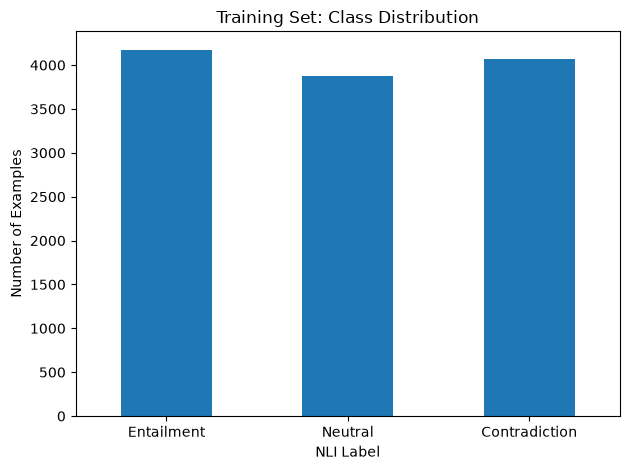

In [6]:
label_counts.plot(kind="bar", rot=0)

plt.title("Training Set: Class Distribution")
plt.xlabel("NLI Label")
plt.ylabel("Number of Examples")
plt.tight_layout()
plt.show()

### 3.4: Examine language distribution

In [7]:
language_counts = train_df["language"].value_counts()

print("Number of languages:", train_df["language"].nunique())
display(language_counts)

Number of languages: 15


language
English       6870
Chinese        411
Arabic         401
French         390
Swahili        385
Urdu           381
Vietnamese     379
Russian        376
Hindi          374
Greek          372
Thai           371
Spanish        366
Turkish        351
German         351
Bulgarian      342
Name: count, dtype: int64

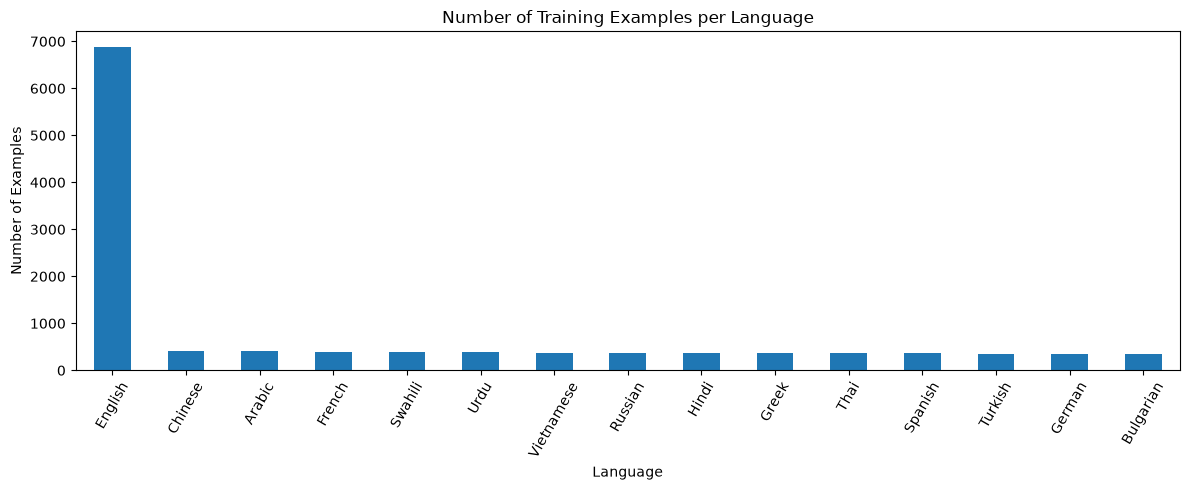

In [8]:
language_counts.plot(kind="bar", figsize=(12, 5), rot=60)

plt.title("Number of Training Examples per Language")
plt.xlabel("Language")
plt.ylabel("Number of Examples")
plt.tight_layout()
plt.show()

### Observation: Language Distribution

The training dataset contains 15 languages. English accounts for 6,870 of the 12,120 examples, approximately 56.7% of the dataset. Each of the remaining 14 languages contributes between 342 and 411 examples.

Thus, although the dataset covers multiple languages, its language distribution is highly imbalanced. This is a property of the dataset, distinct from the distribution of the three NLI classes.

We will keep this observation in mind when interpreting the dataset, without drawing conclusions about model performance before training any models.

### 3.5: Inspect representative sentence pairs

In [9]:
display(
    train_df[
        ["premise", "hypothesis", "language", "label"]
    ].sample(10, random_state=42)
)

,premise,hypothesis,language,label
4960,Кто? Она спросила его с неожиданным интересом.,"Она спросила, как это сделать, так как с её то...",Russian,1
2088,Others are Zao (in Tohoku) and a number of res...,There are a lot of resorts in the national park.,English,0
396,trying to keep grass alive during a summer on ...,There was no cost in keeping the grass alive i...,English,2
6385,so i guess my experience is is just with what ...,They were able to be home rather than having t...,English,0
2619,The Journal put the point succinctly to Is an...,"The Journal asked ""Is this a good political mo...",English,1
2167,"Tuy nhiên, email của nhà phân tích phản ánh rằ...",Nhà phân tích đã không rõ ràng về nhiều thứ.,Vietnamese,0
373,"Ω, παρακαλώ. Υπήρξε πραγματική ανησυχία στη φω...",Η φωνή της έδειξε την ανησυχία της.,Greek,0
6298,yeah okay yeah those games are fun to watch yo...,Those games are a lot of fun.,English,0
7854,ในฐานะสมาชิกของอินเนอร์เซอร์เคิลคุณจะได้รับสิท...,สมาชิกวงใน ไม่ได้รับอะไรเลย ในฐานะที่เป็นสมาชิ...,Thai,2
2392,Another White House murder mystery and a chanc...,White House murder mystery has other works bef...,English,0


In [10]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 20)

display(
    train_df[
        ["premise", "hypothesis", "language", "label"]
    ].sample(5, random_state=42)
)

,premise,hypothesis,language,label
4960,Кто? Она спросила его с неожиданным интересом.,"Она спросила, как это сделать, так как с её точки зрения это казалось невозможным.",Russian,1
2088,"Others are Zao (in Tohoku) and a number of resorts in Joshin-etsu Kogen National Park in the Japan Alps, where there are now splendid facilities thanks to the 1998 Winter Olympic Games in Nagano.",There are a lot of resorts in the national park.,English,0
396,trying to keep grass alive during a summer on a piece of ground that big was expensive,There was no cost in keeping the grass alive in the summer time.,English,2
6385,so i guess my experience is is just with what we did and and so they didn't really go through the child care route they were able to be home together,They were able to be home rather than having to worry about getting child care.,English,0
2619,The Journal put the point succinctly to Is any publicity good publicity?,"The Journal asked ""Is this a good political move?""",English,1


Inspect examples in English

In [11]:
english_df = train_df[train_df["language"] == "English"]

display(
    english_df[
        ["premise", "hypothesis", "label"]
    ].sample(10, random_state=42)
)

,premise,hypothesis,label
5356,"3) Dare you rise to the occasion, like Raskolnikov, and reject the petty rules that govern lesser men?",Would you rise up and defeaat all evil lords in the town?,1
2175,"He married Dona Filipa Moniz (Perestrelo), the daughter of Porto Santo's first governor, and lived on the island for a period, fathering a son there.","He landed on the island but soon left for greener pastures, before later dying alone and childless.",2
7580,The contrast between the landscape of the central highlands and the south coast could not be more marked.,There was a beautiful artist who painted the landscape of the central highlands.,1
3831,i don't know i i do i can think of all the uh the biblical things about it too where what did they say to uh i can't think of the scripture Render unto Caesar's what is Caesar's so,I know this because I own a bible.,1
11542,'So I assume he hacked into the autopilot and reprogrammed it to-',I'm assuming he hacked the autopilot to bring the plane down.,1
2046,"They returned to live in the Galilee village of Nazareth, making pilgrimages to Jerusalem.",They would make pilgrimages to Jerusalem.,0
8729,An Indian traveler described the prosperous Bujang Valley settlement as the seat of all felicities.,A traveler said the settlement was prospering.,0
5166,"TIG funds support the Technology Evaluation Project, an initiative of the Legal Aid Society of Cincinnati.","TIG funds are used to support the Technology Evolution project, a legal aid society in Cincinnati.",0
5385,well i think i got to agree with you there,I could not agree with you.,2
2996,"Say, man, don't you know you've been given up for dead?",You were thought to be dead!,0


Read each example as a pair:

In [15]:
for idx, row in english_df.iterrows():
    print(f"\nExample {idx}")
    print(f"Premise:    {row['premise']}")
    print(f"Hypothesis: {row['hypothesis']}")
    print(f"Label:      {row['label']}")
    print("-" * 80)


Example 0
Premise:    and these comments were considered in formulating the interim rules.
Hypothesis: The rules developed in the interim were put together with these comments in mind.
Label:      0
--------------------------------------------------------------------------------

Example 1
Premise:    These are issues that we wrestle with in practice groups of law firms, she said. 
Hypothesis: Practice groups are not permitted to work on these issues.
Label:      2
--------------------------------------------------------------------------------

Example 3
Premise:    you know they can't really defend themselves like somebody grown uh say my age you know yeah
Hypothesis: They can't defend themselves because of their age.
Label:      0
--------------------------------------------------------------------------------

Example 7
Premise:    From Cockpit Country to St. Ann's Bay
Hypothesis: From St. Ann's Bay to Cockpit Country.
Label:      2
------------------------------------------------

## 3.6 Sentence Length Analysis

Premises and hypotheses can contain different numbers of words. Examining their lengths helps us understand the data and later make informed choices about tokenization and sequence truncation.

We will calculate word counts as a simple first approximation. These counts are not the same as tokenizer token counts: subword tokenizers can split a single word into multiple tokens.

In [16]:
# Approximate sentence lengths using whitespace-separated words
train_df["premise_word_count"] = (
    train_df["premise"].str.split().str.len()
)

train_df["hypothesis_word_count"] = (
    train_df["hypothesis"].str.split().str.len()
)

display(
    train_df[
        ["premise_word_count", "hypothesis_word_count"]
    ].describe()
)

,premise_word_count,hypothesis_word_count
count,12120.000000,12120.000000
mean,17.990182,9.195297
std,12.898411,4.650281
min,1.000000,1.000000
25%,9.000000,6.000000
50%,16.000000,9.000000
75%,25.000000,12.000000
max,196.000000,46.000000


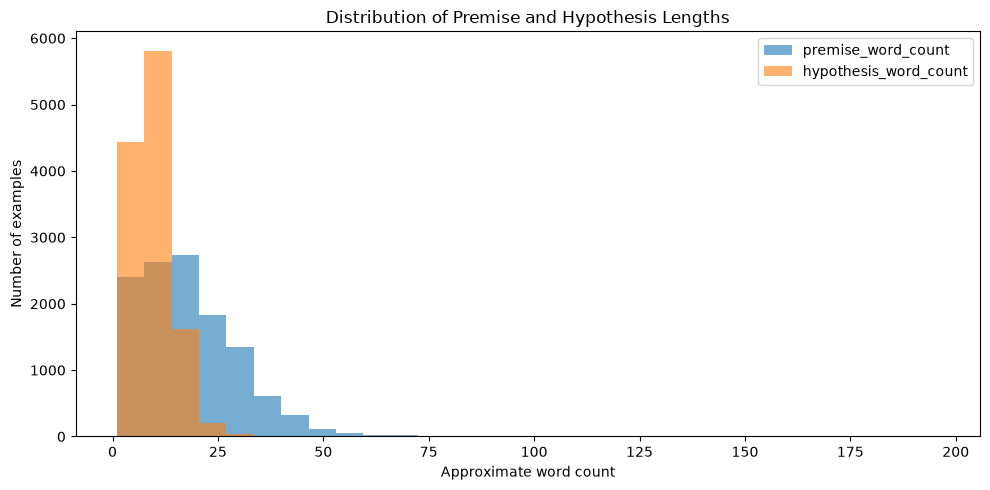

In [17]:
# visualize the distribution
train_df[
    ["premise_word_count", "hypothesis_word_count"]
].plot(
    kind="hist",
    bins=30,
    alpha=0.6,
    figsize=(10, 5),
)

plt.title("Distribution of Premise and Hypothesis Lengths")
plt.xlabel("Approximate word count")
plt.ylabel("Number of examples")
plt.tight_layout()
plt.show()

Next, plot the two distributions separately:

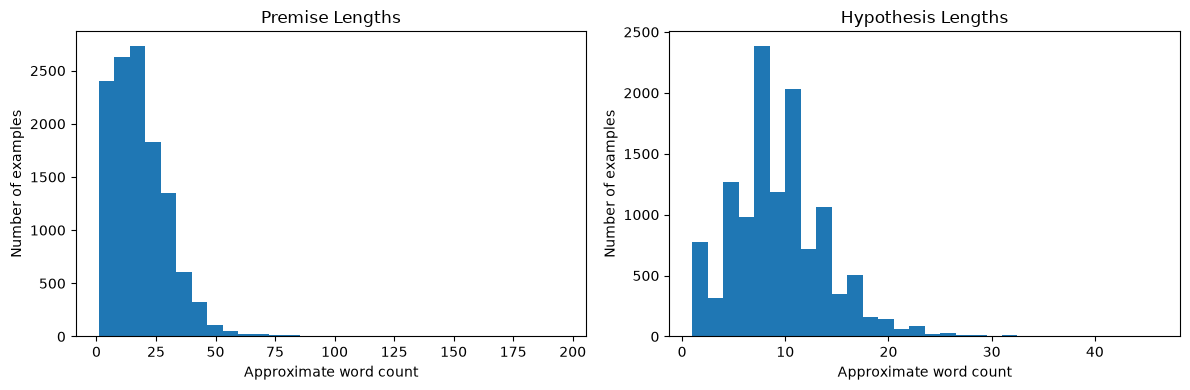

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train_df["premise_word_count"], bins=30)
axes[0].set_title("Premise Lengths")
axes[0].set_xlabel("Approximate word count")
axes[0].set_ylabel("Number of examples")

axes[1].hist(train_df["hypothesis_word_count"], bins=30)
axes[1].set_title("Hypothesis Lengths")
axes[1].set_xlabel("Approximate word count")
axes[1].set_ylabel("Number of examples")

plt.tight_layout()
plt.show()

### Observations: Sentence Lengths

The training set contains 12,120 premise–hypothesis pairs. Premises have a mean length of approximately 18 words and a median of 16, whereas hypotheses have a mean length of approximately 9 words and a median of 9.

Both distributions are right-skewed. The maximum observed lengths are 196 words for premises and 46 words for hypotheses, indicating substantial variability.

These are whitespace-separated word counts, not tokenizer token counts. We will examine tokenization when we begin implementing NLP models.

### 3.7: Check for duplicate entries

In [19]:
print("Duplicate rows:", train_df.duplicated().sum())

print(
    "Duplicate premise-hypothesis pairs:",
    train_df.duplicated(subset=["premise", "hypothesis"]).sum()
)

Duplicate rows: 0
Duplicate premise-hypothesis pairs: 0


## 4. Summary of Exploratory Data Analysis

### Dataset characteristics

- The training set contains 12,120 examples.
- Each example contains a premise, a hypothesis, a language, and a class label.
- The dataset represents 15 languages.
- The target has three classes: entailment (0), neutral (1), and contradiction (2).
- The class distribution is relatively balanced.
- English accounts for approximately 56.7% of the training examples, so the language distribution is highly imbalanced.
- Premises are longer on average than hypotheses.
- The longest premise contains 196 whitespace-separated words; the longest hypothesis contains 46.
- No exact duplicate rows or duplicate premise–hypothesis pairs were found in the training set.

### Limitations of this exploration

These findings describe the training data only. They do not establish how well any model will perform.

Word counts are approximate and do not represent subword-tokenizer lengths. The duplicate checks also do not detect semantically equivalent sentences.

### Conclusion

The dataset is suitable for a three-class Natural Language Inference task. Its multilingual coverage and varying sentence lengths will be important considerations when we begin implementing models.

The next stage is to establish a simple, reproducible baseline before moving to neural networks and pretrained Transformers.